In [1]:
import pandas as pd
customer=pd.read_csv("../Data/SampleCode/Chapter5/customer_join.csv")
uselog_months=pd.read_csv("../Data/SampleCode/Chapter5/use_log_months.csv")

In [ ]:

year_months=list(uselog_months["年月"].unique())
uselog=pd.DataFrame()
for i in range(1,len(year_months)): #1か月前が存在してる必要があるので2018/5から開始
    tmp=uselog_months.loc[uselog_months["年月"]==year_months[i]] #当月の利用履歴
    tmp.rename(columns={"count":"count_0"},inplace=True)
    tmp_before=uselog_months.loc[uselog_months["年月"]==year_months[i-1]] #1か月前の利用履歴
    del tmp_before["年月"]
    tmp_before.rename(columns={"count":"count_1"},inplace=True)
    tmp=pd.merge(tmp,tmp_before,on="customer_id",how="left")
    uselog=pd.concat([uselog,tmp],ignore_index=True)

uselog.head()

/tmp/ipykernel_11235/576266617.py:5: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  tmp.rename(columns={"count":"count_0"},inplace=True)
/tmp/ipykernel_11235/576266617.py:8: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  tmp_before.rename(columns={"count":"count_1"},inplace=True)
/tmp/ipykernel_11235/576266617.py:5: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  tmp.rename(columns={"count":"count_0"},inplace=True)
/tmp/ipykernel_11235/576

,年月,customer_id,count_0,count_1
0,201805,AS002855,5,4.0
1,201805,AS009373,4,3.0
2,201805,AS015233,7,NaN
3,201805,AS015315,3,6.0
4,201805,AS015739,5,7.0


In [ ]:
#退会前月の退会顧客データを作成する(やめる一か月前の利用履歴)
#退会前月なのは1か月前に退会申請して1か月後退会という仕組みなので退会申請した後の当月のデータを用いても退会を防ぐ予測はできないため
exit_customer=customer.loc[customer["is_deleted"]==1]
exit_customer["exit_date"]=None
exit_customer["end_date"]=pd.to_datetime(exit_customer["end_date"])

exit_customer["exit_date"] = exit_customer["end_date"] - pd.DateOffset(months=1)

exit_customer["年月"]=exit_customer["exit_date"].dt.strftime("%Y%m")
uselog["年月"]=uselog["年月"].astype(str)
exit_uselog=pd.merge(uselog,exit_customer,on=["customer_id","年月"],how="left")
print(len(uselog))
exit_uselog.head()

33851


/tmp/ipykernel_11235/337180199.py:4: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  exit_customer["exit_date"]=None
/tmp/ipykernel_11235/337180199.py:5: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  exit_customer["end_date"]=pd.to_datetime(exit_customer["end_date"])
/tmp/ipykernel_11235/337180199.py:7: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.

,年月,customer_id,count_0,count_1,name,class,gender,start_date,end_date,campaign_id,...,price,campaign_name,mean,median,max,min,routine_flg,calc_date,membership_period,exit_date
0,201805,AS002855,5,4.0,NaN,NaN,NaN,NaN,NaT,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaT
1,201805,AS009373,4,3.0,NaN,NaN,NaN,NaN,NaT,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaT
2,201805,AS015233,7,NaN,NaN,NaN,NaN,NaN,NaT,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaT
3,201805,AS015315,3,6.0,NaN,NaN,NaN,NaN,NaT,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaT
4,201805,AS015739,5,7.0,NaN,NaN,NaN,NaN,NaT,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaT


In [ ]:
exit_uselog=exit_uselog.dropna(subset=["name"]) #name列にNaNが入っている行のみ対象
print(len(exit_uselog))
print(len(exit_uselog["customer_id"].unique()))
exit_uselog.head()

1104
1104


,年月,customer_id,count_0,count_1,name,class,gender,start_date,end_date,campaign_id,...,price,campaign_name,mean,median,max,min,routine_flg,calc_date,membership_period,exit_date
19,201805,AS055680,3,3.0,XXXXX,C01,M,2018-03-01,2018-06-30,CA1,...,10500.0,通常,3.000000,3.0,3.0,3.0,0.0,2018-06-30,3.0,2018-05-30
57,201805,AS169823,2,3.0,XX,C01,M,2017-11-01,2018-06-30,CA1,...,10500.0,通常,3.000000,3.0,4.0,2.0,1.0,2018-06-30,7.0,2018-05-30
110,201805,AS305860,5,3.0,XXXX,C01,M,2017-06-01,2018-06-30,CA1,...,10500.0,通常,3.333333,3.0,5.0,2.0,0.0,2018-06-30,12.0,2018-05-30
128,201805,AS363699,5,3.0,XXXXX,C01,M,2018-02-01,2018-06-30,CA1,...,10500.0,通常,3.333333,3.0,5.0,2.0,0.0,2018-06-30,4.0,2018-05-30
147,201805,AS417696,1,4.0,XX,C03,F,2017-09-01,2018-06-30,CA1,...,6000.0,通常,2.000000,1.0,4.0,1.0,0.0,2018-06-30,9.0,2018-05-30


In [ ]:
#継続顧客のデータを作成する
#継続顧客は退会月がないので2018/5のAさんでも2018/12のAさんでも使える
conti_customer=customer.loc[customer["is_deleted"]==0]
conti_uselog=pd.merge(uselog,conti_customer,on=["customer_id"],how="left")
print(len(conti_uselog))
conti_uselog=conti_uselog.dropna(subset=["name"])
print(len(conti_uselog))

33851
27422


In [ ]:
#データをシャッフルして重複を削除する(2018/5のAさんでも2018/12のAさんどっちか選ぶ)
conti_uselog=conti_uselog.sample(frac=1).reset_index(drop=True)
conti_uselog=conti_uselog.drop_duplicates(subset="customer_id") #idが重複しているデータは最初のデータのみ取得
print(len(conti_uselog))
conti_uselog.head()

2842


,年月,customer_id,count_0,count_1,name,class,gender,start_date,end_date,campaign_id,...,class_name,price,campaign_name,mean,median,max,min,routine_flg,calc_date,membership_period
0,201808,PL071673,5,6.0,XXXXX,C03,F,2017-01-01,NaN,CA1,...,ナイト,6000.0,通常,5.500000,5.0,8.0,2.0,1.0,2019-04-30,27.0
1,201808,IK580114,5,5.0,XXXX,C01,M,2015-10-01,NaN,CA1,...,オールタイム,10500.0,通常,4.666667,5.0,8.0,3.0,1.0,2019-04-30,42.0
2,201903,HI292858,4,5.0,XX,C01,M,2017-09-01,NaN,CA1,...,オールタイム,10500.0,通常,5.833333,6.0,9.0,3.0,1.0,2019-04-30,19.0
3,201902,PL556767,5,9.0,XXXX,C01,M,2018-01-01,NaN,CA1,...,オールタイム,10500.0,通常,6.333333,6.5,9.0,5.0,1.0,2019-04-30,15.0
4,201901,GD258009,5,7.0,XXXXX,C01,M,2017-07-01,NaN,CA2,...,オールタイム,10500.0,入会費半額,5.166667,5.0,9.0,1.0,1.0,2019-04-30,21.0


In [11]:
predict_data=pd.concat([conti_uselog,exit_uselog],ignore_index=True)
print(len(predict_data))
predict_data.head()

3946


/tmp/ipykernel_11235/4164445289.py:1: FutureWarning: The behavior of DataFrame concatenation with empty or all-NA entries is deprecated. In a future version, this will no longer exclude empty or all-NA columns when determining the result dtypes. To retain the old behavior, exclude the relevant entries before the concat operation.
  predict_data=pd.concat([conti_uselog,exit_uselog],ignore_index=True)


,年月,customer_id,count_0,count_1,name,class,gender,start_date,end_date,campaign_id,...,price,campaign_name,mean,median,max,min,routine_flg,calc_date,membership_period,exit_date
0,201808,PL071673,5,6.0,XXXXX,C03,F,2017-01-01,NaT,CA1,...,6000.0,通常,5.500000,5.0,8.0,2.0,1.0,2019-04-30,27.0,NaT
1,201808,IK580114,5,5.0,XXXX,C01,M,2015-10-01,NaT,CA1,...,10500.0,通常,4.666667,5.0,8.0,3.0,1.0,2019-04-30,42.0,NaT
2,201903,HI292858,4,5.0,XX,C01,M,2017-09-01,NaT,CA1,...,10500.0,通常,5.833333,6.0,9.0,3.0,1.0,2019-04-30,19.0,NaT
3,201902,PL556767,5,9.0,XXXX,C01,M,2018-01-01,NaT,CA1,...,10500.0,通常,6.333333,6.5,9.0,5.0,1.0,2019-04-30,15.0,NaT
4,201901,GD258009,5,7.0,XXXXX,C01,M,2017-07-01,NaT,CA2,...,10500.0,入会費半額,5.166667,5.0,9.0,1.0,1.0,2019-04-30,21.0,NaT


In [13]:
#在籍期間のデータを追加する
from dateutil.relativedelta import relativedelta
predict_data["period"]=0
predict_data["now_date"]=pd.to_datetime(predict_data["年月"],format="%Y%m")
predict_data["start_date"]=pd.to_datetime(predict_data["start_date"])
for i in range(len(predict_data)):
    delta=relativedelta(predict_data.loc[i,"now_date"],predict_data.loc[i,"start_date"])
    predict_data.loc[i,"period"]=int(delta.years*12+delta.months)

predict_data.head()

,年月,customer_id,count_0,count_1,name,class,gender,start_date,end_date,campaign_id,...,mean,median,max,min,routine_flg,calc_date,membership_period,exit_date,period,now_date
0,201808,PL071673,5,6.0,XXXXX,C03,F,2017-01-01,NaT,CA1,...,5.500000,5.0,8.0,2.0,1.0,2019-04-30,27.0,NaT,19,2018-08-01
1,201808,IK580114,5,5.0,XXXX,C01,M,2015-10-01,NaT,CA1,...,4.666667,5.0,8.0,3.0,1.0,2019-04-30,42.0,NaT,34,2018-08-01
2,201903,HI292858,4,5.0,XX,C01,M,2017-09-01,NaT,CA1,...,5.833333,6.0,9.0,3.0,1.0,2019-04-30,19.0,NaT,18,2019-03-01
3,201902,PL556767,5,9.0,XXXX,C01,M,2018-01-01,NaT,CA1,...,6.333333,6.5,9.0,5.0,1.0,2019-04-30,15.0,NaT,13,2019-02-01
4,201901,GD258009,5,7.0,XXXXX,C01,M,2017-07-01,NaT,CA2,...,5.166667,5.0,9.0,1.0,1.0,2019-04-30,21.0,NaT,18,2019-01-01


In [14]:
#欠損値処理
predict_data.isna().sum()

年月                      0
customer_id             0
count_0                 0
count_1               253
name                    0
class                   0
gender                  0
start_date              0
end_date             2842
campaign_id             0
is_deleted              0
class_name              0
price                   0
campaign_name           0
mean                    0
median                  0
max                     0
min                     0
routine_flg             0
calc_date               0
membership_period       0
exit_date            2842
period                  0
now_date                0
dtype: int64

In [16]:
predict_data=predict_data.dropna(subset=["count_1"])
predict_data.isna().sum()

年月                      0
customer_id             0
count_0                 0
count_1                 0
name                    0
class                   0
gender                  0
start_date              0
end_date             2641
campaign_id             0
is_deleted              0
class_name              0
price                   0
campaign_name           0
mean                    0
median                  0
max                     0
min                     0
routine_flg             0
calc_date               0
membership_period       0
exit_date            2641
period                  0
now_date                0
dtype: int64

In [17]:
#文字列型の変数をよりできるようにする(カテゴリカル変数をダミー変数化する)
target_col=["campaign_name","class_name","gender","count_1","routine_flg","period","is_deleted"]
predict_data=predict_data[target_col]
predict_data.head()

,campaign_name,class_name,gender,count_1,routine_flg,period,is_deleted
0,通常,ナイト,F,6.0,1.0,19,0.0
1,通常,オールタイム,M,5.0,1.0,34,0.0
2,通常,オールタイム,M,5.0,1.0,18,0.0
3,通常,オールタイム,M,9.0,1.0,13,0.0
4,入会費半額,オールタイム,M,7.0,1.0,18,0.0


In [18]:
predict_data=pd.get_dummies(predict_data) #ダミー変数化
predict_data.head()

,count_1,routine_flg,period,is_deleted,campaign_name_入会費半額,campaign_name_入会費無料,campaign_name_通常,class_name_オールタイム,class_name_デイタイム,class_name_ナイト,gender_F,gender_M
0,6.0,1.0,19,0.0,False,False,True,False,False,True,True,False
1,5.0,1.0,34,0.0,False,False,True,True,False,False,False,True
2,5.0,1.0,18,0.0,False,False,True,True,False,False,False,True
3,9.0,1.0,13,0.0,False,False,True,True,False,False,False,True
4,7.0,1.0,18,0.0,True,False,False,True,False,False,False,True


In [19]:
#明らかな不要な列を削除する
#例えば女性か男性かなら女性列に1が格納されてれば女性なので男性列は必要ない
del predict_data["campaign_name_通常"]
del predict_data["class_name_ナイト"]
del predict_data["gender_M"]
predict_data.head()

,count_1,routine_flg,period,is_deleted,campaign_name_入会費半額,campaign_name_入会費無料,class_name_オールタイム,class_name_デイタイム,gender_F
0,6.0,1.0,19,0.0,False,False,False,False,True
1,5.0,1.0,34,0.0,False,False,True,False,False
2,5.0,1.0,18,0.0,False,False,True,False,False
3,9.0,1.0,13,0.0,False,False,True,False,False
4,7.0,1.0,18,0.0,True,False,True,False,False


In [ ]:
#決定木を用いて退会予測モデルを作成する
from sklearn.tree import DecisionTreeClassifier
import sklearn.model_selection

exit=predict_data.loc[predict_data["is_deleted"]==1]
conti=predict_data.loc[predict_data["is_deleted"]==0].sample(len(exit)) #ランダム抽出してexitの件数とそろえる

X=pd.concat([exit,conti],ignore_index=True)
y=X["is_deleted"]
del X["is_deleted"] #訓練用データに答えはあっちゃダメ
X_train,X_test,y_train,y_test=sklearn.model_selection.train_test_split(X,y) 

model=DecisionTreeClassifier(random_state=0)
model.fit(X_train,y_train)
y_test_pred=model.predict(X_test)
print(y_test_pred) #1は退会,0は継続

[0. 0. 1. 0. 1. 0. 1. 0. 0. 0. 0. 0. 0. 0. 1. 0. 1. 1. 1. 1. 0. 1. 1. 1.
 0. 1. 0. 1. 1. 0. 1. 0. 1. 1. 1. 0. 1. 1. 1. 1. 1. 1. 0. 1. 1. 0. 1. 0.
 0. 1. 0. 1. 1. 0. 0. 0. 0. 0. 0. 1. 0. 0. 0. 0. 0. 1. 0. 0. 1. 0. 1. 0.
 0. 0. 1. 1. 1. 1. 1. 1. 1. 1. 0. 0. 1. 1. 1. 0. 0. 1. 1. 0. 0. 1. 0. 0.
 1. 0. 0. 0. 0. 0. 1. 1. 1. 0. 0. 0. 0. 1. 1. 0. 0. 1. 0. 1. 1. 0. 0. 1.
 1. 1. 1. 1. 1. 1. 1. 0. 1. 1. 0. 1. 1. 1. 1. 1. 1. 1. 1. 1. 0. 1. 0. 0.
 0. 1. 0. 1. 1. 1. 0. 1. 0. 0. 0. 0. 1. 0. 0. 0. 1. 0. 1. 1. 1. 1. 0. 0.
 0. 1. 0. 0. 0. 0. 0. 0. 0. 0. 1. 1. 0. 0. 0. 0. 0. 0. 1. 0. 1. 0. 0. 0.
 0. 0. 0. 0. 0. 0. 1. 1. 1. 0. 0. 0. 0. 1. 1. 1. 0. 0. 0. 0. 1. 0. 1. 0.
 0. 0. 1. 0. 0. 1. 0. 1. 0. 0. 1. 1. 0. 1. 0. 1. 0. 0. 0. 0. 0. 0. 1. 0.
 1. 1. 0. 1. 1. 0. 0. 1. 1. 0. 0. 0. 1. 0. 1. 0. 0. 0. 1. 0. 1. 0. 0. 1.
 1. 1. 0. 0. 1. 1. 1. 0. 0. 1. 1. 1. 1. 1. 0. 1. 0. 0. 1. 0. 1. 1. 1. 0.
 0. 1. 0. 1. 1. 0. 0. 0. 0. 0. 1. 1. 1. 1. 0. 1. 1. 1. 1. 0. 1. 1. 1. 1.
 1. 0. 0. 1. 1. 1. 0. 1. 1. 1. 0. 1. 0. 0. 0. 0. 1.

In [21]:
#正解との比較をするために保存
results_test=pd.DataFrame({"y_test":y_test,"y_pred":y_test_pred})
results_test.head()

,y_test,y_pred
1700,0.0,0.0
1533,0.0,0.0
285,1.0,1.0
1530,0.0,0.0
325,1.0,1.0


In [23]:
#モデルの評価
correct=len(results_test.loc[results_test["y_test"]==results_test["y_pred"]])
data_count=len(results_test)
score_test=correct/data_count
print(score_test)

print(model.score(X_train,y_train))#簡潔に書く

0.903041825095057
0.9803548795944234


In [42]:
#過学習傾向にあるのでモデルを簡易化する
X=pd.concat([exit,conti],ignore_index=True)
y=X["is_deleted"]
del X["is_deleted"]
X_train,X_test,y_train,y_test=sklearn.model_selection.train_test_split(X,y) 

model=DecisionTreeClassifier(random_state=0,max_depth=5)
model.fit(X_train,y_train)
print(model.score(X_test,y_test))
print(model.score(X_train,y_train))

0.9277566539923955
0.9252217997465145


In [43]:
#モデルに寄与している変数を確認する
importance=pd.DataFrame({"feature_names":X.columns,"coefficient":model.feature_importances_})
importance

,feature_names,coefficient
0,count_1,0.348950
1,routine_flg,0.115083
2,period,0.531945
3,campaign_name_入会費半額,0.004022
4,campaign_name_入会費無料,0.000000
5,class_name_オールタイム,0.000000
6,class_name_デイタイム,0.000000
7,gender_F,0.000000


/usr/local/lib/python3.12/dist-packages/sklearn/tree/_export.py:673: UserWarning: Glyph 20837 (\N{CJK UNIFIED IDEOGRAPH-5165}) missing from font(s) DejaVu Sans.
  ann.update_bbox_position_size(renderer)
/usr/local/lib/python3.12/dist-packages/sklearn/tree/_export.py:673: UserWarning: Glyph 20250 (\N{CJK UNIFIED IDEOGRAPH-4F1A}) missing from font(s) DejaVu Sans.
  ann.update_bbox_position_size(renderer)
/usr/local/lib/python3.12/dist-packages/sklearn/tree/_export.py:673: UserWarning: Glyph 36027 (\N{CJK UNIFIED IDEOGRAPH-8CBB}) missing from font(s) DejaVu Sans.
  ann.update_bbox_position_size(renderer)
/usr/local/lib/python3.12/dist-packages/sklearn/tree/_export.py:673: UserWarning: Glyph 21322 (\N{CJK UNIFIED IDEOGRAPH-534A}) missing from font(s) DejaVu Sans.
  ann.update_bbox_position_size(renderer)
/usr/local/lib/python3.12/dist-packages/sklearn/tree/_export.py:673: UserWarning: Glyph 38989 (\N{CJK UNIFIED IDEOGRAPH-984D}) missing from font(s) DejaVu Sans.
  ann.update_bbox_position_

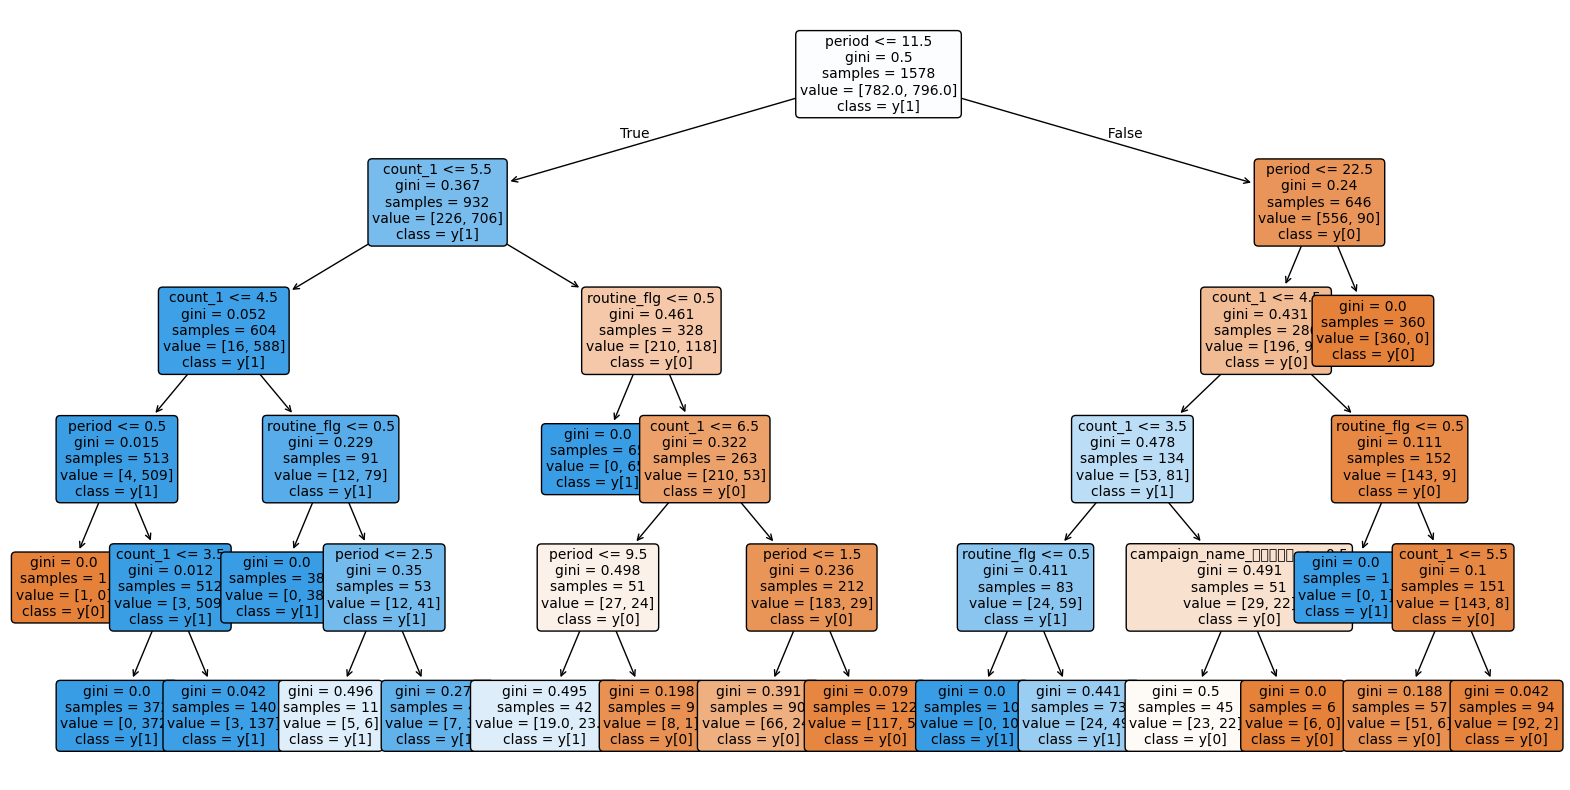

In [45]:
#決定木を可視化する
from sklearn.tree import plot_tree
import matplotlib.pyplot as plt

plt.figure(figsize=(20, 10))

plot_tree(
    model, 
    feature_names=X.columns,  # 特徴量（列名）のリスト
    class_names=True,         # クラス名
    filled=True,              # 色を塗って分かりやすくする
    rounded=True,             # 角を丸くする
    fontsize=10               # 文字の大きさ
)

plt.show()